## Question

Which of five large technology companies came through the two crashes of 2000 to 2010 best, and how can titles, annotations, direct labels and a formatted table carry that answer without a legend lookup?

The data is the **stocks** file of the vega-datasets collection ([vega/vega-datasets](https://github.com/vega/vega-datasets) on GitHub). It has 560 monthly share prices in US dollars for Apple, Amazon, Google, IBM and Microsoft. Four of the companies run from January 2000 to March 2010 (123 months each). Google enters in August 2004, the month of its initial public offering, and has 68 months. The decade holds two crashes: the end of the dot-com boom, which took technology shares down from early 2000 to 2002 and 2003, and the financial crisis that followed the bankruptcy of Lehman Brothers on 15 September 2008.

::: {.callout-note appearance="simple" collapse=true}
## Data source

Stocks file: <https://github.com/vega/vega-datasets/blob/main/data/stocks.csv>

The copy in this submission, `stocks.csv`, was written from the version bundled with the `vega_datasets` Python package, with dates in ISO format. It has three columns: `symbol`, `date` and `price`.
:::

## Reproducibility

The notebook reads `stocks.csv` from the same folder and has no manual steps or random numbers, so the render does not depend on the network. The packages are pinned in `requirements.txt` (`pip install -r requirements.txt`). The cell below prints the versions used for this render.

In [1]:
import sys
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import great_tables
from great_tables import GT
from matplotlib.offsetbox import AnchoredText, AnnotationBbox, TextArea
plt.rcParams["figure.dpi"] = 150
print("python", sys.version.split()[0])
print("pandas", pd.__version__)
print("matplotlib", matplotlib.__version__)
print("great_tables", great_tables.__version__)

python 3.13.16
pandas 3.0.5
matplotlib 3.11.2
great_tables 1.0.0


In [2]:
#| output: asis
stocks = pd.read_csv("stocks.csv", parse_dates=["date"])
names = {"AAPL": "Apple", "AMZN": "Amazon", "GOOG": "Google", "IBM": "IBM", "MSFT": "Microsoft"}
stocks["company"] = stocks["symbol"].map(names)
prices = stocks.pivot(index="date", columns="company", values="price")
print(stocks.shape[0], "rows,", prices.shape[1], "companies,", prices.shape[0], "months")
print()
tail = prices.tail()
tail.index = tail.index.strftime("%b %Y")
print(tail.to_markdown(floatfmt=".2f"))

560 rows, 5 companies, 123 months

| date     |   Amazon |   Apple |   Google |    IBM |   Microsoft |
|:---------|---------:|--------:|---------:|-------:|------------:|
| Nov 2009 |   135.91 |  199.91 |   583.00 | 125.79 |       29.27 |
| Dec 2009 |   134.52 |  210.73 |   619.98 | 130.32 |       30.34 |
| Jan 2010 |   125.41 |  192.06 |   529.94 | 121.85 |       28.05 |
| Feb 2010 |   118.40 |  204.62 |   526.80 | 127.16 |       28.67 |
| Mar 2010 |   128.82 |  223.02 |   560.19 | 125.55 |       28.80 |


The file is long, one row per company and month, so `pivot` turns it into one column per company indexed by date. The tickers become company names first, so every label in the charts and the table uses the same name.

## Annotated chart: Apple across the decade

The first chart follows one company over the whole file. Apple has the widest range of the five, from $7.07 to $223.02, so it carries both crashes in a single line. Three annotations mark the March 2003 low, the release of the iPhone in June 2007 and the Lehman Brothers bankruptcy in September 2008, and each gives a date and a price.

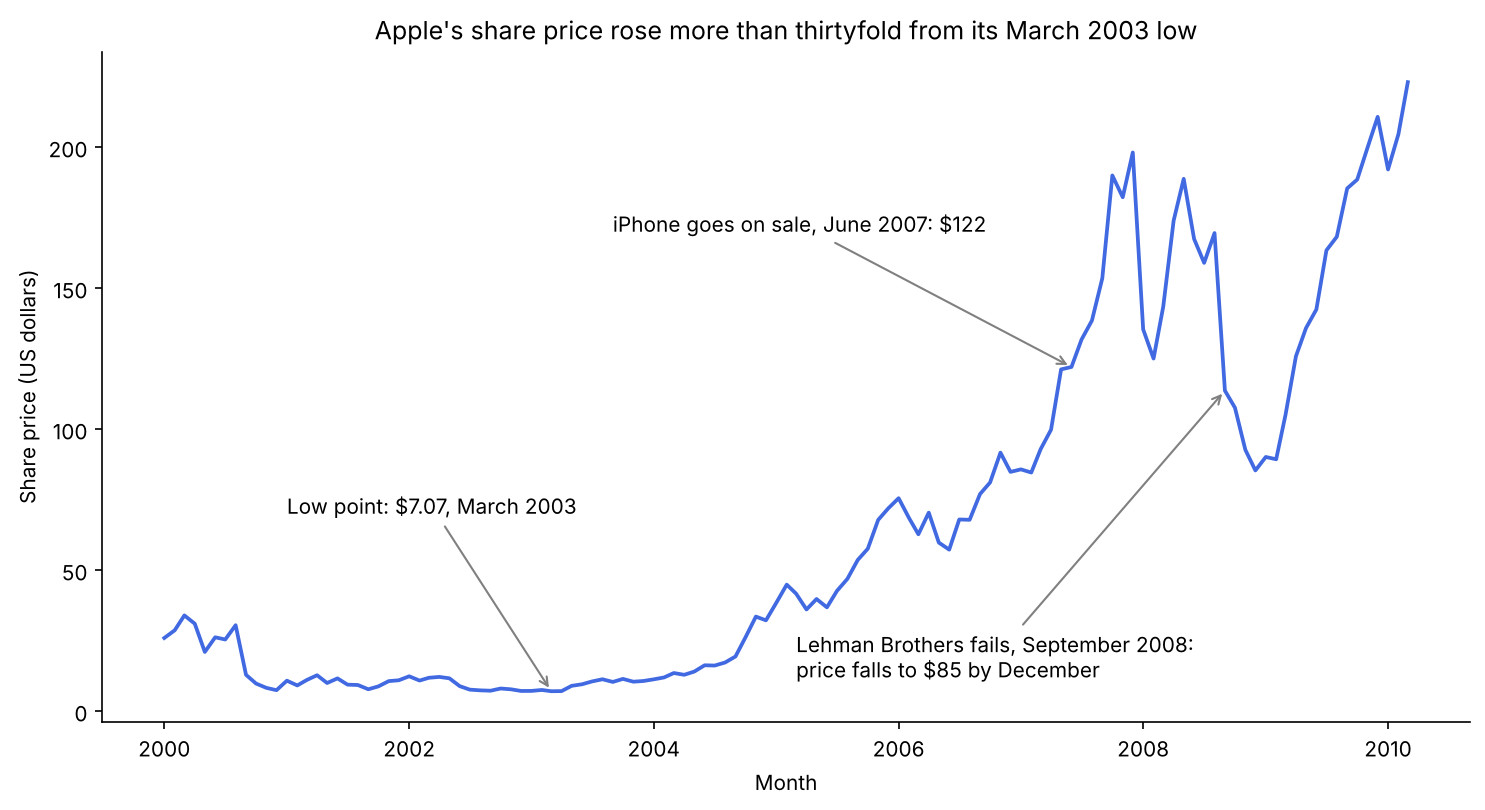

In [3]:
apple = prices["Apple"]
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.plot(apple.index, apple, color="royalblue", linewidth=1.8)
ax.annotate("Low point: $7.07, March 2003", xy=(pd.Timestamp("2003-03-01"), 7.07), xytext=(pd.Timestamp("2001-01-01"), 70), arrowprops=dict(arrowstyle="->", color="grey"))
ax.annotate("iPhone goes on sale, June 2007: $122", xy=(pd.Timestamp("2007-06-01"), 122.04), xytext=(pd.Timestamp("2003-09-01"), 170), arrowprops=dict(arrowstyle="->", color="grey"))
ax.annotate("Lehman Brothers fails, September 2008:\nprice falls to $85 by December", xy=(pd.Timestamp("2008-09-01"), 113.66), xytext=(pd.Timestamp("2005-03-01"), 12), arrowprops=dict(arrowstyle="->", color="grey"))
ax.set_xlabel("Month")
ax.set_ylabel("Share price (US dollars)")
ax.set_title("Apple's share price rose more than thirtyfold from its March 2003 low")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

Apple lost 79 percent of its value in the first crash, from $33.95 in March 2000 to $7.07 in March 2003, and spent most of 2001 and 2002 near $10. The climb starts in 2004 and is already steep before the iPhone: the price is $122.04 in June 2007 and peaks at $198.08 in December 2007. The second crash takes it to $85.35 in December 2008, a fall of 57 percent in twelve months. By March 2010 the price is $223.02, 2.6 times the December 2008 level and above the 2007 peak.

## Directly labeled chart: five companies from August 2004

The second chart compares all five companies from August 2004, the first month with a Google price. Each series is set to 100 in that month, so a value of 300 means the price tripled. The y axis is logarithmic, so equal vertical distances are equal percentage changes. The chart has no legend: each line carries its company name and its March 2010 value at its right end, in the line's own color.

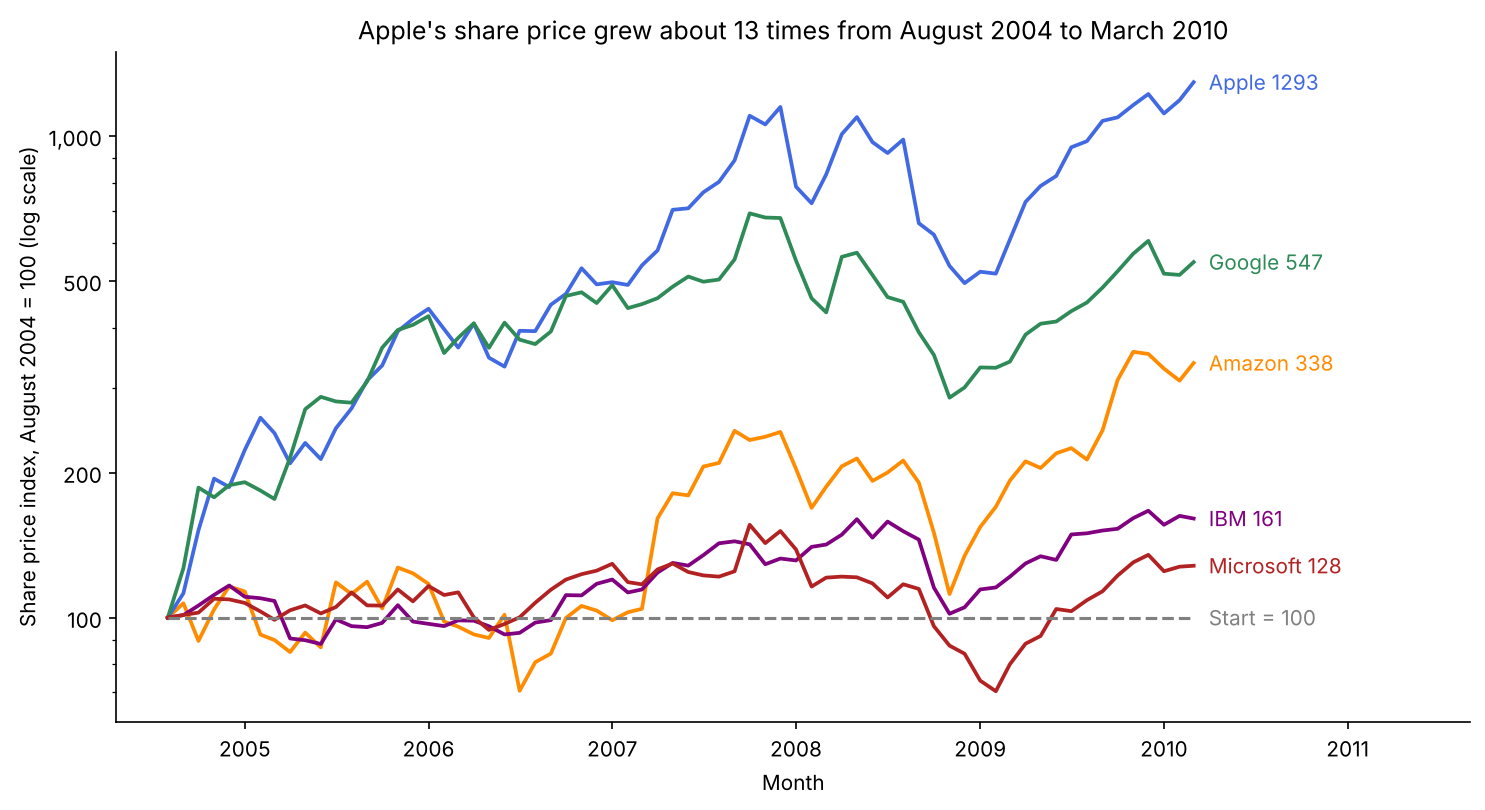

In [4]:
indexed = prices.loc["2004-08-01":] / prices.loc["2004-08-01"] * 100
colors = {"Apple": "royalblue", "Amazon": "darkorange", "Google": "seagreen", "IBM": "purple", "Microsoft": "firebrick"}
label_x = indexed.index[-1] + pd.Timedelta(days=30)
fig, ax = plt.subplots(figsize=(10, 5.5))
for company in indexed.columns:
    ax.plot(indexed.index, indexed[company], color=colors[company], linewidth=1.8)
    ax.text(label_x, indexed[company].iloc[-1], f"{company} {indexed[company].iloc[-1]:.0f}", color=colors[company], va="center")
ax.plot([indexed.index[0], indexed.index[-1]], [100, 100], color="grey", linestyle="--")
ax.text(label_x, 100, "Start = 100", color="grey", va="center")
ax.set_yscale("log")
ax.set_yticks([100, 200, 500, 1000])
ax.set_yticklabels(["100", "200", "500", "1,000"])
ax.set_xlim(right=pd.Timestamp("2011-09-01"))
ax.set_xlabel("Month")
ax.set_ylabel("Share price index, August 2004 = 100 (log scale)")
ax.set_title("Apple's share price grew about 13 times from August 2004 to March 2010")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

The five lines split into two groups. Apple and Google run together until 2007, then Apple pulls away and ends at 1,293 against 547 for Google. Amazon ends at 338 after dropping to 70.5 in July 2006, the lowest point of any company in the first two years. IBM and Microsoft stay close to the start line for the whole period and end at 161 and 128. The 2008 crisis hits every company in the same months: from October 2007 to December 2008 Apple falls from 1,101 to 495 and Google from 691 to 301. Microsoft is the only one that drops well below its starting level, to 70.4 in February 2009.

## Formatted table: prices, peaks and worst falls

The table gives the dollar figures behind the two charts and adds a measure neither chart shows directly, the worst drawdown: the largest fall of each company from a previous monthly peak. It uses each company's full series, from January 2000 or, for Google, from August 2004. Rows are sorted by the change over the whole series.

In [5]:
drawdown = prices / prices.cummax() - 1
summary = pd.DataFrame()
summary["First month"] = prices.notna().idxmax().dt.strftime("%b %Y")
summary["First price"] = prices.bfill().iloc[0]
summary["March 2010 price"] = prices.iloc[-1]
summary["Change"] = summary["March 2010 price"] / summary["First price"] - 1
summary["Peak price"] = prices.max()
summary["Peak month"] = prices.idxmax().dt.strftime("%b %Y")
summary["Worst drawdown"] = drawdown.min()
summary["Drawdown low"] = drawdown.idxmin().dt.strftime("%b %Y")
summary = summary.sort_values("Change", ascending=False).reset_index()
table = GT(summary, rowname_col="company")
table = table.tab_header(title="Five technology share prices, 2000 to 2010", subtitle="Monthly prices in US dollars; Google from its August 2004 listing")
table = table.tab_spanner(label="Price", columns=["First month", "First price", "March 2010 price", "Change"])
table = table.tab_spanner(label="Peak and worst fall", columns=["Peak price", "Peak month", "Worst drawdown", "Drawdown low"])
table = table.fmt_currency(columns=["First price", "March 2010 price", "Peak price"], currency="USD")
table = table.fmt_percent(columns=["Change", "Worst drawdown"], decimals=0)
table = table.data_color(columns="Change", palette=["white", "seagreen"])
table = table.data_color(columns="Worst drawdown", palette=["firebrick", "white"])
table = table.cols_align(align="right", columns=["First month", "Peak month", "Drawdown low"])
table = table.tab_source_note("Source: stocks.csv, vega-datasets. Worst drawdown is the largest fall from a previous monthly peak.")
table

GT(_tbl_data=     company First month  First price  March 2010 price    Change  Peak price  \
0      Apple    Jan 2000        25.94            223.02  7.597533      223.02   
1     Google    Aug 2004       102.37            560.19  4.472209      707.00   
2     Amazon    Jan 2000        64.56            128.82  0.995353      135.91   
3        IBM    Jan 2000       100.52            125.55  0.249005      130.32   
4  Microsoft    Jan 2000        39.81             28.80 -0.276564       43.22   

  Peak month  Worst drawdown Drawdown low  
0   Mar 2010       -0.791753     Mar 2003  
1   Oct 2007       -0.585629     Nov 2008  
2   Nov 2009       -0.913315     Sep 2001  
3   Dec 2009       -0.553111     Sep 2002  
4   Mar 2000       -0.634197     Feb 2009  , _body=<great_tables._gt_data.Body object at 0x7f64e180d550>, _boxhead=Boxhead([ColInfo(var='company', type=<ColInfoTypeEnum.stub: 2>, column_label='company', column_align='left', column_width=None), ColInfo(var='First month', type=<ColInfoTypeEnum.default: 1>, column_label='First month', column_align='right', column_width=None), ColInfo(var='First price', type=<ColInfoTypeEnum.default: 1>, column_label='First price', column_align='right', column_width=None), ColInfo(var='March 2010 price', type=<ColInfoTypeEnum.default: 1>, column_label='March 2010 price', column_align='right', column_width=None), ColInfo(var='Change', type=<ColInfoTypeEnum.default: 1>, column_label='Change', column_align='right', column_width=None), ColInfo(var='Peak price', type=<ColInfoTypeEnum.default: 1>, column_label='Peak price', column_align='right', column_width=None), ColInfo(var='Peak month', type=<ColInfoTypeEnum.default: 1>, column_label='Peak month', column_align='right', column_width=None), ColInfo(var='Worst drawdown', type=<ColInfoTypeEnum.default: 1>, column_label='Worst drawdown', column_align='right', column_width=None), ColInfo(var='Drawdown low', type=<ColInfoTypeEnum.default: 1>, column_label='Drawdown low', column_align='right', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x7f64e180d2b0>, _spanners=Spanners([SpannerInfo(spanner_id='Price', spanner_level=0, spanner_label='Price', spanner_units=None, spanner_pattern=None, vars=['First month', 'First price', 'March 2010 price', 'Change'], built=None), SpannerInfo(spanner_id='Peak and worst fall', spanner_level=0, spanner_label='Peak and worst fall', spanner_units=None, spanner_pattern=None, vars=['Peak price', 'Peak month', 'Worst drawdown', 'Drawdown low'], built=None)]), _heading=Heading(title='Five technology share prices, 2000 to 2010', subtitle='Monthly prices in US dollars; Google from its August 2004 listing', preheader=None), _stubhead=None, _summary_rows=<great_tables._gt_data.SummaryRows object at 0x7f64e180d940>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x7f64e1039450>, _source_notes=['Source: stocks.csv, vega-datasets. Worst drawdown is the largest fall from a previous monthly peak.'], _footnotes=[], _styles=[StyleInfo(locname=LocBody(columns='Change', rows=[0], mask=None), grpname=None, colname='Change', rownum=0, colnum=None, styles=[CellStyleText(color='#000000', font=None, size=None, align=None, v_align=None, style=None, weight=None, stretch=None, decorate=None, transform=None, whitespace=None), CellStyleFill(color='#2e8b57')]), StyleInfo(locname=LocBody(columns='Change', rows=[1], mask=None), grpname=None, colname='Change', rownum=1, colnum=None, styles=[CellStyleText(color='#000000', font=None, size=None, align=None, v_align=None, style=None, weight=None, stretch=None, decorate=None, transform=None, whitespace=None), CellStyleFill(color='#81b99a')]), StyleInfo(locname=LocBody(columns='Change', rows=[2], mask=None), grpname=None, colname='Change', rownum=2, colnum=None, styles=[CellStyleText(color='#000000', font=None, size=None, align=None, v_align=None, style=None, weight=None, stretch=None, decorate=None, transform=None, whitespace=None), CellStyleFill(color='#ddece4')]), St

Amazon has the deepest fall of the five, 91 percent from its early 2000 level to September 2001, and still doubles its January 2000 price by March 2010. Microsoft is the only company that ends below where it started, at $28.80 against $39.81, and its peak of $43.22 dates from March 2000. Its worst fall, 63 percent, comes in the second crash, while Apple, Amazon and IBM hit their worst point in the first. Google's worst fall, 59 percent to November 2008, is the only one recorded entirely inside the financial crisis.

## Extension: offsetbox callouts and custom text placement

This chart follows Amazon, the company with the deepest fall of the five. It uses `matplotlib.offsetbox` in two ways. Two boxed callouts are `AnnotationBbox` objects holding a `TextArea`, each anchored to a data point by an arrow. A summary note is an `AnchoredText`, pinned to a corner of the axes whatever the data does. The source line is placed by hand in axes coordinates (`transform=ax.transAxes`), so it stays at the bottom right corner at any figure size.

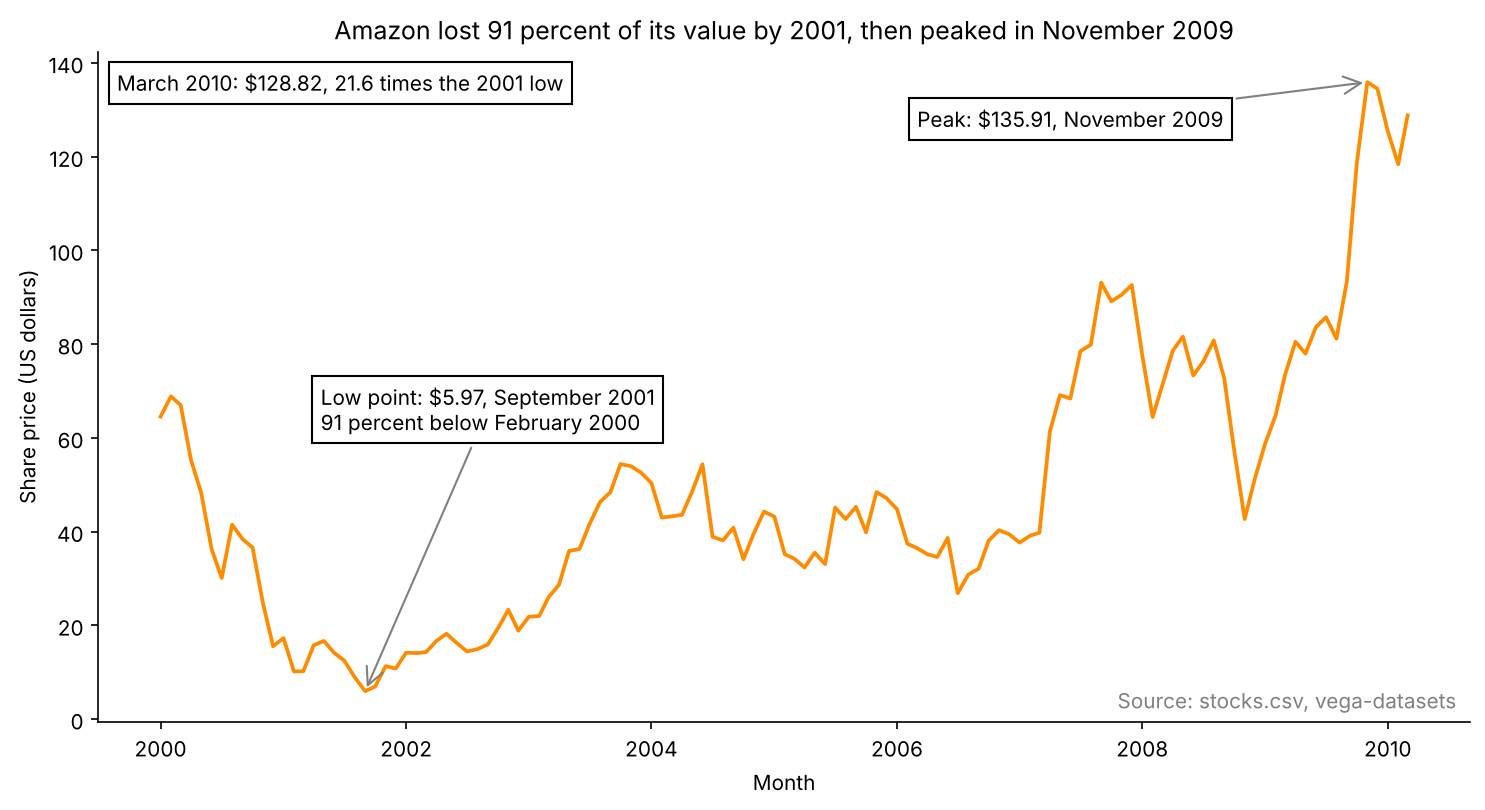

In [6]:
amazon = prices["Amazon"]
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.plot(amazon.index, amazon, color="darkorange", linewidth=1.8)
low_box = TextArea("Low point: $5.97, September 2001\n91 percent below February 2000")
ax.add_artist(AnnotationBbox(low_box, (pd.Timestamp("2001-09-01"), 5.97), xybox=(pd.Timestamp("2002-09-01"), 66), arrowprops=dict(arrowstyle="->", color="grey")))
peak_box = TextArea("Peak: $135.91, November 2009")
ax.add_artist(AnnotationBbox(peak_box, (pd.Timestamp("2009-11-01"), 135.91), xybox=(pd.Timestamp("2007-06-01"), 128), arrowprops=dict(arrowstyle="->", color="grey")))
ax.add_artist(AnchoredText("March 2010: $128.82, 21.6 times the 2001 low", loc="upper left"))
ax.text(0.99, 0.02, "Source: stocks.csv, vega-datasets", transform=ax.transAxes, ha="right", color="grey")
ax.set_xlabel("Month")
ax.set_ylabel("Share price (US dollars)")
ax.set_title("Amazon lost 91 percent of its value by 2001, then peaked in November 2009")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

Amazon fell from $68.87 in February 2000 to $5.97 in September 2001, a loss of 91 percent in nineteen months. It took until 2007 to pass the 2000 level, fell again from $92.64 in December 2007 to $42.70 in November 2008, and reached its peak of $135.91 in November 2009. The boxed callouts suit this chart because the two extremes sit at opposite corners of the plot, and a box keeps each label readable where it crosses the line.

## Extension: color and font to rank the annotations

This chart follows Microsoft, the only company that ended below its January 2000 price. The line is grey, so the annotations carry the color. Color and font weight rank the three annotations by importance: the low is red, bold and larger, the peak is green and bold, and the March 2010 note is blue and italic. A light red band marks the financial crisis, from Microsoft's October 2007 high to its February 2009 low.

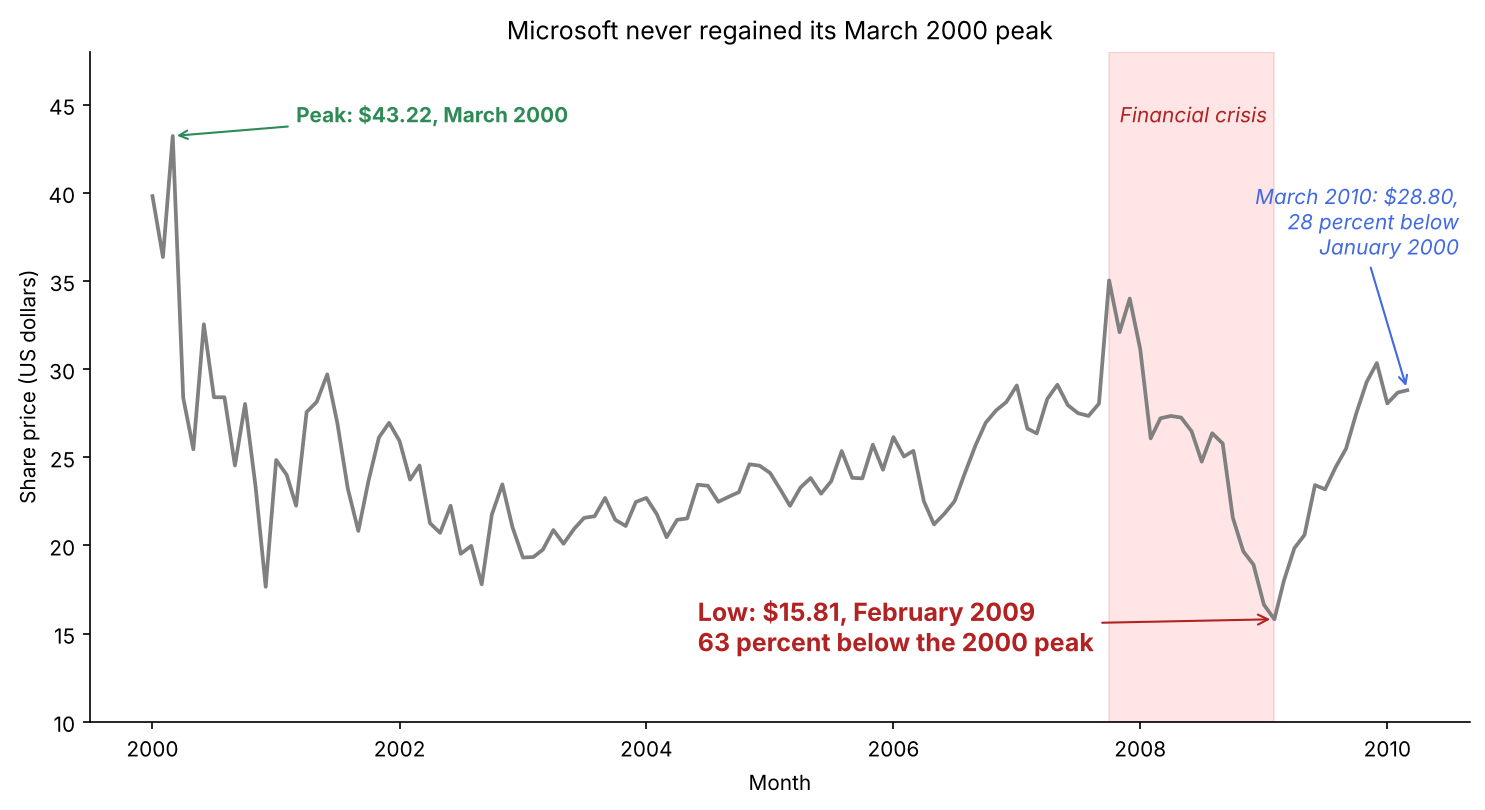

In [7]:
microsoft = prices["Microsoft"]
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.plot(microsoft.index, microsoft, color="grey", linewidth=1.8)
ax.axvspan(pd.Timestamp("2007-10-01"), pd.Timestamp("2009-02-01"), color="red", alpha=0.1)
ax.text(pd.Timestamp("2007-11-01"), 44, "Financial crisis", color="firebrick", fontstyle="italic")
ax.annotate("Peak: $43.22, March 2000", xy=(pd.Timestamp("2000-03-01"), 43.22), xytext=(pd.Timestamp("2001-03-01"), 44), color="seagreen", fontweight="bold", arrowprops=dict(arrowstyle="->", color="seagreen"))
ax.annotate("Low: $15.81, February 2009\n63 percent below the 2000 peak", xy=(pd.Timestamp("2009-02-01"), 15.81), xytext=(pd.Timestamp("2004-06-01"), 14), color="firebrick", fontweight="bold", fontsize=12, arrowprops=dict(arrowstyle="->", color="firebrick"))
ax.annotate("March 2010: $28.80,\n28 percent below\nJanuary 2000", xy=(pd.Timestamp("2010-03-01"), 28.80), xytext=(pd.Timestamp("2010-08-01"), 36.5), ha="right", color="royalblue", fontstyle="italic", arrowprops=dict(arrowstyle="->", color="royalblue"))
ax.set_ylim(10, 48)
ax.set_xlabel("Month")
ax.set_ylabel("Share price (US dollars)")
ax.set_title("Microsoft never regained its March 2000 peak")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

Microsoft lost 59 percent within 2000, from $43.22 in March to $17.65 in December, and spent most of the decade between $20 and $35. The crisis took it from $35.03 in October 2007 to $15.81 in February 2009, its lowest point in the file and 63 percent below the 2000 peak. The red, bold low is the first thing the eye reaches, which matches its weight in the story: it is the reason Microsoft ends the decade below where it began.

## Extension: styled DataFrame exported to LaTeX

The last extension rebuilds the summary table with the pandas `Styler` in place of great_tables, then exports it to LaTeX. Percentages are converted to whole numbers and the units move into the column names, so no cell holds a `$` or `%` sign that LaTeX would need escaped. Two color gradients repeat the shading of the great_tables version. `to_latex` with `convert_css=True` turns those gradients into `\cellcolor` commands, and the file `summary_table.tex` compiles in a LaTeX document that loads `\usepackage[table]{xcolor}`.

In [8]:
export = summary.copy()
export["Change"] = export["Change"] * 100
export["Worst drawdown"] = export["Worst drawdown"] * 100
export = export.rename(columns={"company": "Company", "First price": "First price, USD", "March 2010 price": "March 2010 price, USD", "Change": "Change, percent", "Peak price": "Peak price, USD", "Worst drawdown": "Worst drawdown, percent"})
styled = export.style
styled = styled.format(precision=2)
styled = styled.format(precision=0, subset=["Change, percent", "Worst drawdown, percent"])
styled = styled.hide(axis="index")
styled = styled.background_gradient(subset=["Change, percent"], cmap="Greens")
styled = styled.background_gradient(subset=["Worst drawdown, percent"], cmap="Reds_r")
styled = styled.set_caption("Five technology share prices, 2000 to 2010")
latex = styled.to_latex(hrules=True, convert_css=True)
open("summary_table.tex", "w").write(latex)
print(latex)
styled

\begin{table}
\caption{Five technology share prices, 2000 to 2010}
\begin{tabular}{llrrrrlrl}
\toprule
Company & First month & First price, USD & March 2010 price, USD & Change, percent & Peak price, USD & Peak month & Worst drawdown, percent & Drawdown low \\
\midrule
Apple & Jan 2000 & 25.94 & 223.02 & {\cellcolor[HTML]{00441B}} \color[HTML]{F1F1F1} 760 & 223.02 & Mar 2010 & {\cellcolor[HTML]{E43027}} \color[HTML]{F1F1F1} -79 & Mar 2003 \\
Google & Aug 2004 & 102.37 & 560.19 & {\cellcolor[HTML]{4AAF61}} \color[HTML]{F1F1F1} 447 & 707.00 & Oct 2007 & {\cellcolor[HTML]{FEE6DA}} \color[HTML]{000000} -59 & Nov 2008 \\
Amazon & Jan 2000 & 64.56 & 128.82 & {\cellcolor[HTML]{DCF2D7}} \color[HTML]{000000} 100 & 135.91 & Nov 2009 & {\cellcolor[HTML]{67000D}} \color[HTML]{F1F1F1} -91 & Sep 2001 \\
IBM & Jan 2000 & 100.52 & 125.55 & {\cellcolor[HTML]{EDF8EA}} \color[HTML]{000000} 25 & 130.32 & Dec 2009 & {\cellcolor[HTML]{FFF5F0}} \color[HTML]{000000} -55 & Sep 2002 \\
Microsoft & Jan 2000 & 39

Company,First month,"First price, USD","March 2010 price, USD","Change, percent","Peak price, USD",Peak month,"Worst drawdown, percent",Drawdown low
Apple,Jan 2000,25.94,223.02,760,223.02,Mar 2010,-79,Mar 2003
Google,Aug 2004,102.37,560.19,447,707.00,Oct 2007,-59,Nov 2008
Amazon,Jan 2000,64.56,128.82,100,135.91,Nov 2009,-91,Sep 2001
IBM,Jan 2000,100.52,125.55,25,130.32,Dec 2009,-55,Sep 2002
Microsoft,Jan 2000,39.81,28.80,-28,43.22,Mar 2000,-63,Feb 2009


## Reflection

Both charts carry titles that state the finding, so the reader gets the conclusion first. Each y axis label names its unit, US dollars in the first chart and an index with its base month in the second, because a bare number gives no scale. The three annotations on the Apple chart sit at the months where the line turns, and each gives a date and a price.

The second chart drops the legend and labels each line at its right end. A legend sends the eye back and forth between the key and the data, and with five colors that matching is slow. The end labels also print the March 2010 index value, so each label is itself a data point. The log scale keeps IBM and Microsoft readable next to Apple's thirteenfold rise.

The table holds the dollar figures that the charts cannot show precisely, along with the month and depth of each company's worst fall. Sorting by change puts the companies in the same order as the line ends. Color appears only on the two percentage columns, green for gains and red for losses, so the shading marks the comparison.

## Discussion

The directly labeled chart best answers the question. Indexing to one month puts five prices that range from $16 to $707 on a shared scale, and the end labels give the ranking as one number per company: 1,293 for Apple against 128 for Microsoft. The cost is that it starts in August 2004 and leaves out the first crash.

That first crash is where the annotated charts and the table come in. The Apple, Amazon and Microsoft charts show the 2000 to 2003 falls, and the table gives the worst drawdown of each company, from 55 percent for IBM to 91 percent for Amazon. Read together, they show that the size of the fall did not decide the outcome: Amazon fell the furthest and doubled its price, while Microsoft fell less and ended below its start.

Source: vega-datasets, `data/stocks.csv`, [vega/vega-datasets](https://github.com/vega/vega-datasets) on GitHub, retrieved through the `vega_datasets` Python package, October 2026.